In [2]:
import zipfile
import pandas as pd
from google.colab import files

# Upload the ZIP file from your computer
uploaded = files.upload()

# Get the uploaded ZIP filename
zip_name = next(iter(uploaded))

# Extract the files
with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("student_data")

# Load the mathematics dataset
df = pd.read_csv(
    "student_data/student-mat.csv",
    sep=";"
)

# Display the first five rows
print(df.head())

Saving IDC409_Project_raw_data.zip to IDC409_Project_raw_data.zip
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [3]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nBasic statistics:")
print(df.describe())

Dataset size: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Basic statistics:
              age        Medu        Fedu  traveltime   

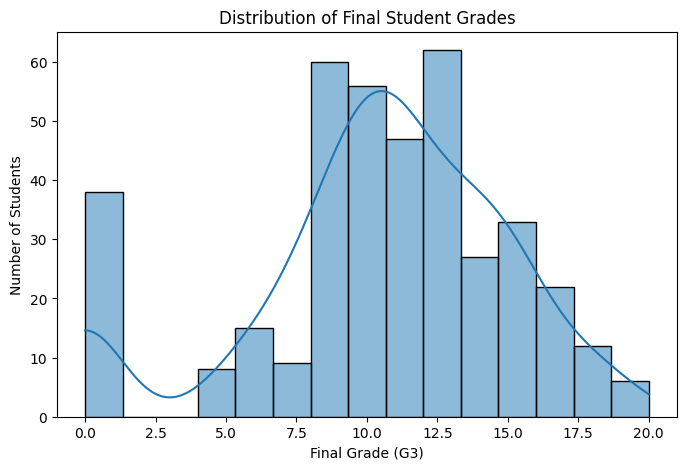

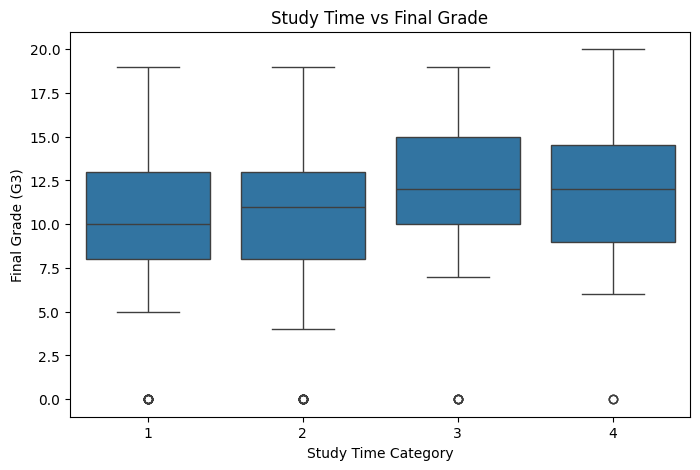

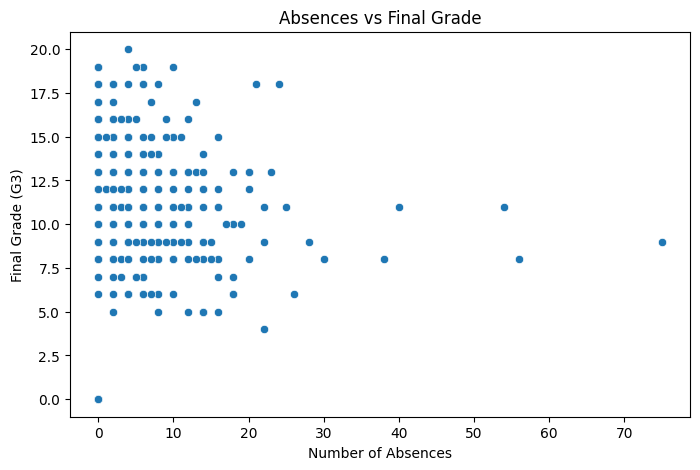

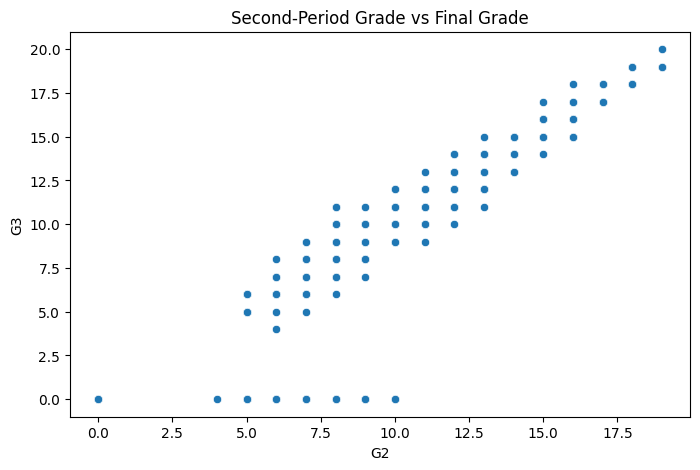

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: Distribution of final grades
plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()


# Graph 2: Study time versus final grade
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.show()


# Graph 3: Absences versus final grade
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.show()


# Graph 4: Previous grades versus final grade
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="G2", y="G3")

plt.title("Second-Period Grade vs Final Grade")
plt.xlabel("G2")
plt.ylabel("G3")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# Input features: everything except the final grade
X = df.drop(columns=["G3"])

# Target: the grade we want to predict
y = df["G3"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", X_train.shape[0])
print("Testing examples:", X_test.shape[0])

Training examples: 316
Testing examples: 79


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Process numerical columns
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical columns
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training complete!")

Random Forest training complete!


In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Predictions from Random Forest
y_pred = rf_model.predict(X_test)

# Baseline model: always predicts the average training grade
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)


def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{name}")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²:   {r2:.3f}")


evaluate_model("Baseline Model", y_test, baseline_pred)
evaluate_model("Random Forest", y_test, y_pred)


Baseline Model
MAE:  3.646
RMSE: 4.550
R²:   -0.010

Random Forest
MAE:  1.205
RMSE: 2.027
R²:   0.800


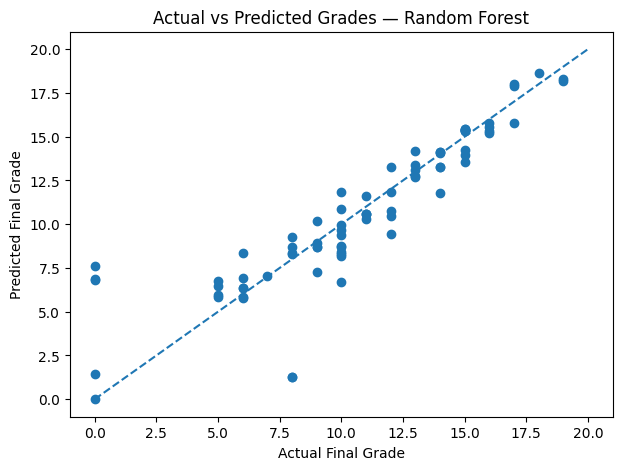

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

# Ideal prediction line
plt.plot([0, 20], [0, 20], linestyle="--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Grades — Random Forest")
plt.show()

                 Feature  Importance
14               num__G2    0.795710
12         num__absences    0.116984
36      cat__reason_home    0.017763
0               num__age    0.009912
13               num__G1    0.005021
6            num__famrel    0.004085
11           num__health    0.003943
35    cat__reason_course    0.003816
40  cat__guardian_mother    0.003556
8             num__goout    0.002681
56      cat__romantic_no    0.002358
43    cat__schoolsup_yes    0.002179
10             num__Walc    0.002167
42     cat__schoolsup_no    0.002028
2              num__Fedu    0.001891


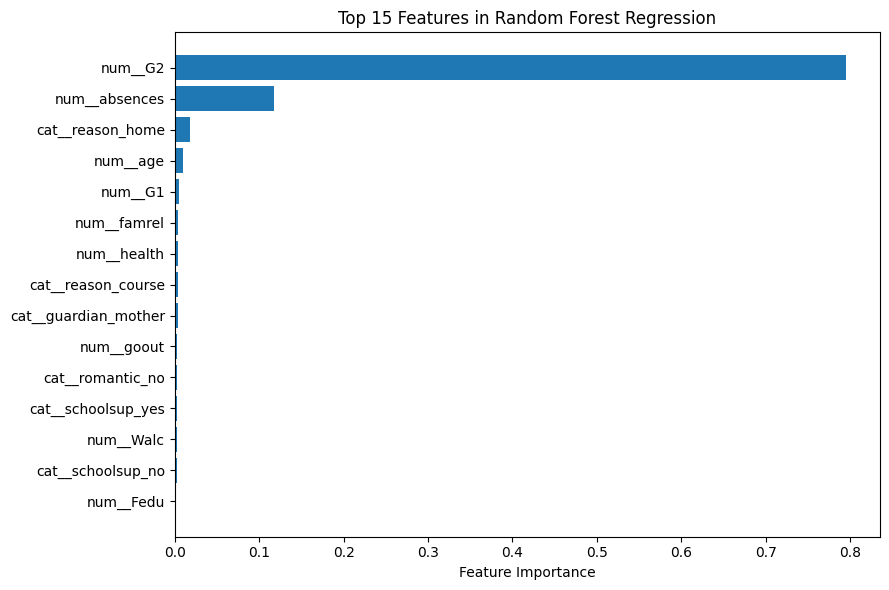

In [9]:
# Get the transformed feature names after preprocessing
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get the Random Forest's importance scores
importances = (
    rf_model.named_steps["model"].feature_importances_
)

# Put the results in a table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features in Random Forest Regression")
plt.tight_layout()
plt.show()